In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [2]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)

train_df = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/titanic/test.csv")
print("train shape:", train_df.shape, "test shape:", test_df.shape)


train shape: (891, 12) test shape: (418, 11)


In [3]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
test_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.1+ KB


In [7]:
train_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
train_df.describe(include=["object"])

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


In [9]:
test_df.describe()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


In [ ]:
#fare is a skewed data!

In [10]:
test_df.describe(include=['object'])

,Name,Sex,Ticket,Cabin,Embarked
count,418,418,418,91,418
unique,418,2,363,76,3
top,"Peter, Master. Michael J",male,PC 17608,B57 B59 B63 B66,S
freq,1,266,5,3,270


In [11]:
print("train duplications:", train_df.duplicated().sum())
print("test duplications:", test_df.duplicated().sum())

train duplications: 0
test duplications: 0


In [12]:
#to have the baseline for accuracy -- 0 = dead, 1 = alive
print(train_df['Survived'].value_counts())
train_df['Survived'].value_counts(normalize=True)*100

Survived
0    549
1    342
Name: count, dtype: int64


Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [13]:
columns_to_check = ["Survived","Pclass","Sex","SibSp","Parch","Embarked"]
for col in columns_to_check:
    print(train_df[col].value_counts(dropna=False))

Survived
0    549
1    342
Name: count, dtype: int64
Pclass
3    491
1    216
2    184
Name: count, dtype: int64
Sex
male      577
female    314
Name: count, dtype: int64
SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64
Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


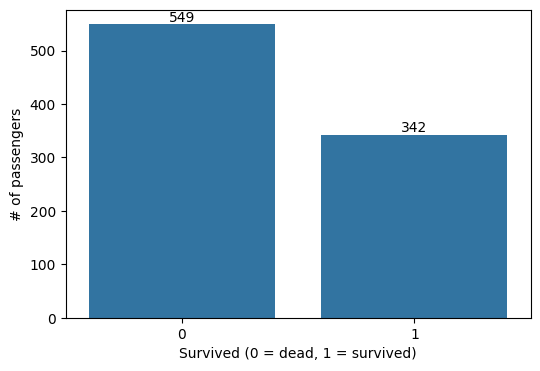

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

ax = sns.countplot(data=train_df, x='Survived')
plt.xlabel('Survived (0 = dead, 1 = survived)')
plt.ylabel('# of passengers')
ax.bar_label(ax.containers[0]) 
plt.show()

In [15]:
#sex vs survived
train_df.groupby('Sex')['Survived'].agg(['count', 'mean'])

,count,mean
Sex,,
female,314,0.742038
male,577,0.188908


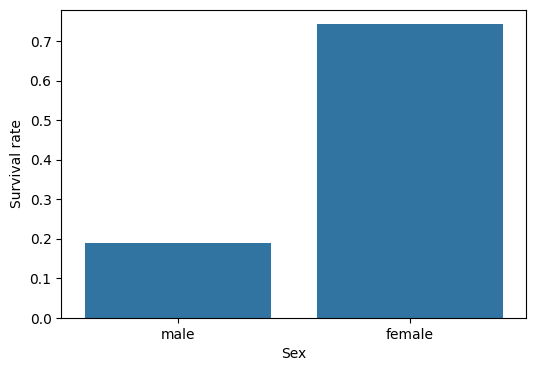

In [16]:
plt.figure(figsize=(6,4))
sns.barplot(data=train_df, x='Sex', y='Survived', errorbar=None)
plt.xlabel("Sex")
plt.ylabel('Survival rate')
plt.show()

In [17]:
#passenger class vs survived
train_df.groupby('Pclass')['Survived'].agg(['count', 'mean'])

,count,mean
Pclass,,
1,216,0.629630
2,184,0.472826
3,491,0.242363


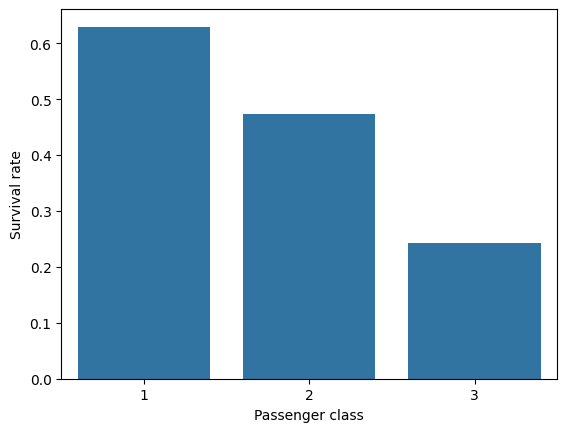

In [18]:
sns.barplot(data=train_df, x='Pclass', y='Survived', errorbar=None)
plt.xlabel('Passenger class')
plt.ylabel('Survival rate')
plt.show()

In [19]:
#sex and passenger class vs survival
train_df.groupby(['Sex', 'Pclass'])['Survived'].agg(['count', 'mean'])

count      mean
Sex    Pclass                 
female 1          94  0.968085
       2          76  0.921053
       3         144  0.500000
male   1         122  0.368852
       2         108  0.157407
       3         347  0.135447

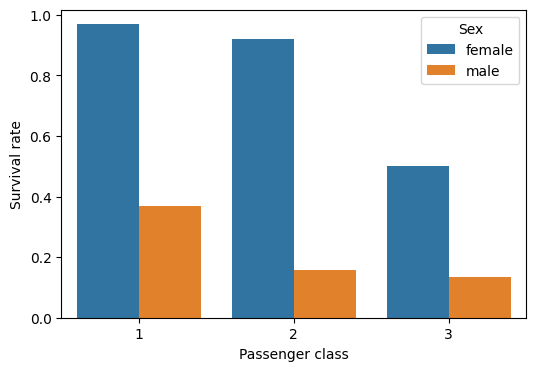

In [20]:
plt.figure(figsize=(6,4))
sns.barplot(data=train_df, x='Pclass', y='Survived', hue='Sex', errorbar=None)
plt.xlabel('Passenger class')
plt.ylabel('Survival rate')
plt.show()

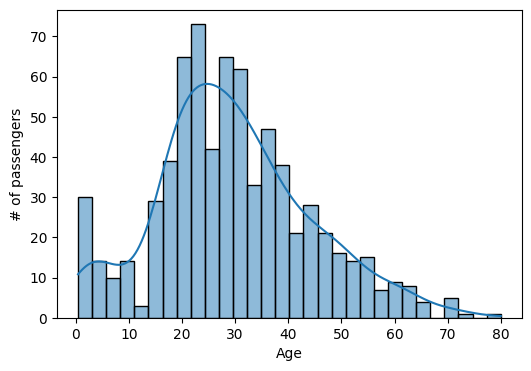

In [21]:
#age vs survived 
plt.figure(figsize=(6,4))
sns.histplot(data=train_df, x='Age', bins=30, kde=True)
plt.xlabel('Age')
plt.ylabel('# of passengers')
plt.show()

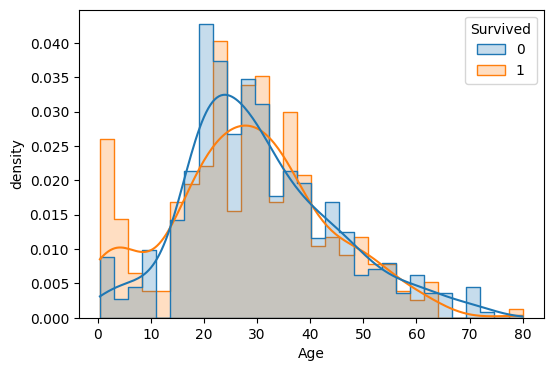

In [22]:
#survival at different ages
plt.figure(figsize=(6,4))
sns.histplot(data=train_df, x='Age', hue='Survived', bins=30, kde=True, element='step', stat='density', common_norm=False)
plt.xlabel('Age')
plt.ylabel('density')
plt.show()

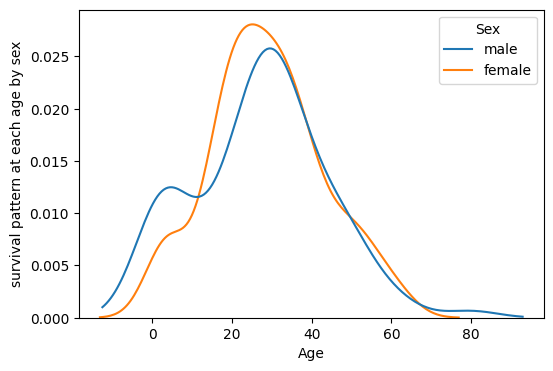

In [23]:
#age and sex
plt.figure(figsize=(6,4))
sns.kdeplot(data=train_df, x='Age', hue='Sex', weights='Survived', multiple='layer', common_norm=False)
plt.xlabel('Age')
plt.ylabel('survival pattern at each age by sex')
plt.show()

In [24]:
eda_df = train_df.copy()
eda_df['Age_group']=pd.cut(eda_df['Age'], bins=[0,12, 18, 30, 45, 60, 100], 
                           labels=['child', 'teen', 'young', 'adult', 'older_adult', 'old'])

eda_df.groupby('Age_group')['Survived'].agg(['count', 'mean'])

/tmp/ipykernel_27506/3606465443.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  eda_df.groupby('Age_group')['Survived'].agg(['count', 'mean'])


,count,mean
Age_group,,
child,69,0.579710
teen,70,0.428571
young,270,0.355556
adult,202,0.425743
older_adult,81,0.407407
old,22,0.227273


In [25]:
eda_df.groupby(['Age_group', 'Sex'], observed=False)['Survived'].agg(['count', 'mean'])

count      mean
Age_group   Sex                    
child       female     32  0.593750
            male       37  0.567568
teen        female     36  0.750000
            male       34  0.088235
young       female     90  0.755556
            male      180  0.155556
adult       female     73  0.780822
            male      129  0.224806
older_adult female     27  0.851852
            male       54  0.185185
old         female      3  1.000000
            male       19  0.105263

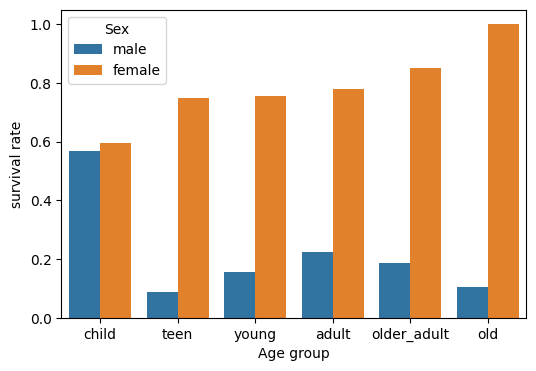

In [26]:
plt.figure(figsize=(6,4))
sns.barplot(data=eda_df, x='Age_group', y = 'Survived', hue='Sex', errorbar=None)
plt.xlabel('Age group')
plt.ylabel('survival rate')
plt.show()

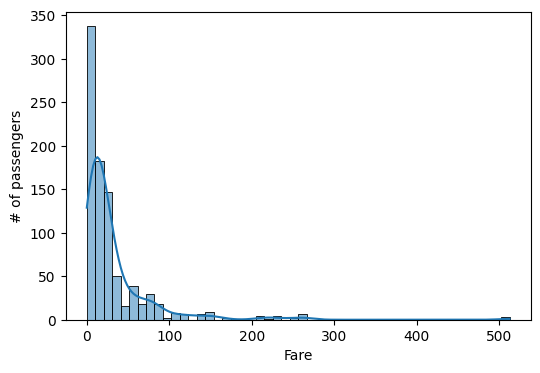

In [27]:
#Fare vs survived
plt.figure(figsize=(6,4))
sns.histplot(data=train_df, x='Fare', bins= 50, kde=True)
plt.xlabel('Fare')
plt.ylabel('# of passengers')
plt.show()

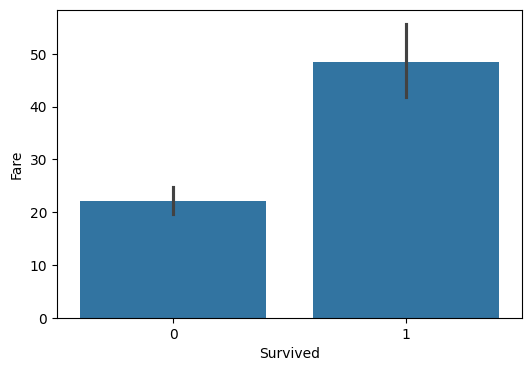

In [28]:
plt.figure(figsize=(6,4))
sns.barplot(data=train_df, x='Survived', y='Fare')
plt.xlabel('Survived')
plt.ylabel('Fare')
plt.show()

In [29]:
#embarked vs survived
train_df.groupby('Embarked')['Survived'].agg(['count', 'mean'])

,count,mean
Embarked,,
C,168,0.553571
Q,77,0.389610
S,644,0.336957


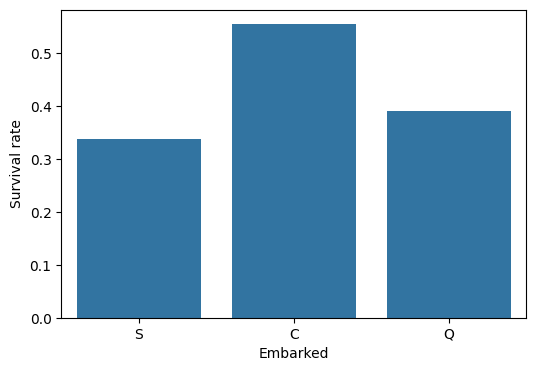

In [30]:
plt.figure(figsize=(6,4))
sns.barplot(data=train_df, x='Embarked', y = 'Survived', errorbar=None)
plt.xlabel('Embarked')
plt.ylabel('Survival rate')
plt.show()

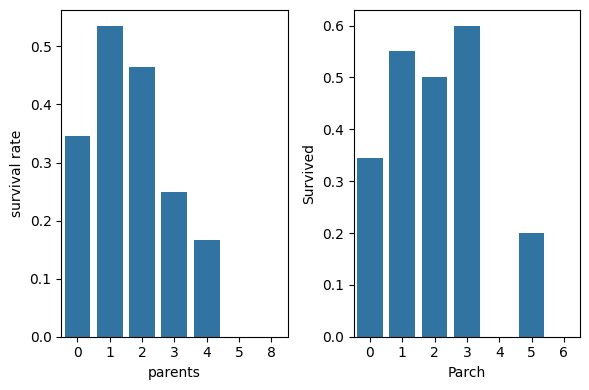

In [31]:
#siblngs / parents vs survived
fig, axes = plt.subplots(1,2, figsize=(6,4))
sns.barplot(data=train_df, x = 'SibSp', y='Survived', errorbar=None, ax= axes[0])
axes[0].set_xlabel('sibling')
axes[0].set_ylabel('survival rate')
sns.barplot(data=train_df, x = 'Parch', y='Survived', errorbar=None, ax= axes[1])
axes[0].set_xlabel('parents')
axes[0].set_ylabel('survival rate')
plt.tight_layout()
plt.show()

Notes so far:
1. Sex by far is the most indicator (F=74%, M=19%)
2. Passenger class is also important (1st class = 64%, 2nd class 47%, 3rd class= 24%)
3. Sex and passenger class is really interesting result
        
4. Age and sex together was interesting too - gender in children has no affect but teenage and young girls were survived way more than teenage boys -- note: old women survived 100% but there are only 3 old women --> sample size issue 

5. Fare is skewed towards right!passenger who survived also paid more for the ticket (richer) -- we had it before via passenger class

6. Embarked is not clear how it might affect

7. Family size has some effect probably

In [ ]:
# majority_baseline = (train_df['Survived'] == 0).mean()
# majority_baseline #~62% did not survive

In [ ]:
# female_gender = (train_df['Sex']=='female').astype(int)
# gender_baseline = (female_gender == train_df['Survived']).mean()
# print(gender_baseline) #alive ones 

In [32]:
#logistic regression 

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


numerical_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Sex', 'Pclass', 'Embarked']
features = numerical_features + categorical_features
X = train_df[features].copy()
y=train_df['Survived'].copy()
print(X.shape, y.shape)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_val.shape, y_train.shape, y_val.shape)

(891, 7) (891,)
(712, 7) (179, 7) (712,) (179,)


In [33]:
#data cleaning - none values in Age and scales, etc
numerical_transformer = Pipeline(steps = [("imputer", SimpleImputer(strategy = 'median')), 
                                           ("scaler", StandardScaler())])
categorical_transformer = Pipeline(steps = [("imputer", SimpleImputer(strategy = 'most_frequent')),
                                           ("encoder", OneHotEncoder(handle_unknown='ignore', drop='first'))])
preprocessor = ColumnTransformer(transformers=[("num", numerical_transformer, numerical_features),
                                               ("cat", categorical_transformer, categorical_features)])

In [34]:
logreg = Pipeline(steps=[("preprocessor", preprocessor),('classifier', LogisticRegression(max_iter=1000, random_state=42))])


In [35]:
logreg.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['Sex', 'Pclass',
                                                   'Embarked'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [36]:
y_train_pred = logreg.predict(X_train)
y_val_pred = logreg.predict(X_val)

In [37]:
#evaluation
train_accuracy = accuracy_score(y_train, y_train_pred)
val_accuracy = accuracy_score(y_val, y_val_pred)
print(f"Training accuracy:{train_accuracy:.4f}")
print(f"Validation accuracy:{val_accuracy:.4f}")

Training accuracy:0.8104
Validation accuracy:0.7989


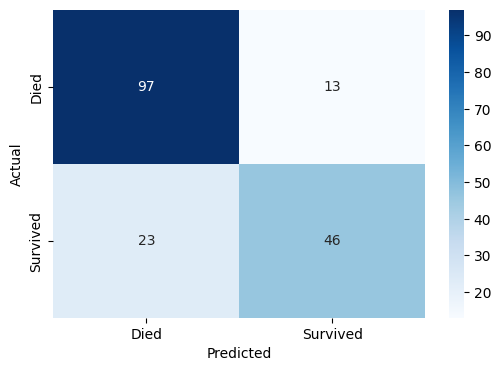

In [38]:
cm = confusion_matrix(y_val, y_val_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Died','Survived'], yticklabels=['Died','Survived'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [39]:
print(classification_report(y_val, y_val_pred, target_names=["Died", "Survived"]))

              precision    recall  f1-score   support

        Died       0.81      0.88      0.84       110
    Survived       0.78      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.80      0.80      0.80       179



In [40]:
feature_names = (logreg.named_steps["preprocessor"].get_feature_names_out())
coefficients = (logreg.named_steps["classifier"].coef_[0])
coef_df = pd.DataFrame({"Feature": feature_names,"Coefficient": coefficients})
coef_df = coef_df.sort_values("Coefficient")
coef_df

,Feature,Coefficient
4,cat__Sex_male,-2.529833
6,cat__Pclass_3,-1.919663
5,cat__Pclass_2,-0.734868
0,num__Age,-0.468895
8,cat__Embarked_S,-0.438453
1,num__SibSp,-0.260728
2,num__Parch,-0.069937
3,num__Fare,0.174708
7,cat__Embarked_Q,0.228675


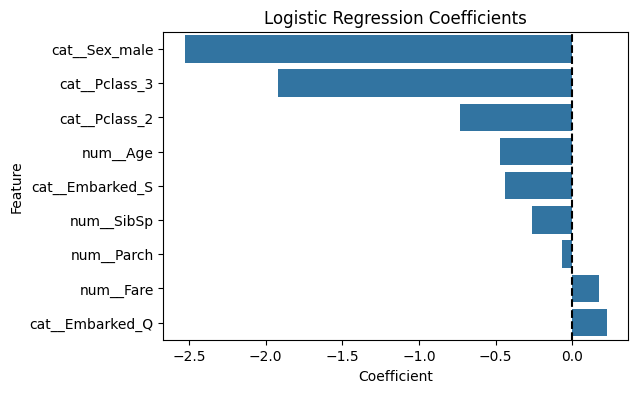

In [41]:
plt.figure(figsize=(6, 4))

sns.barplot(data=coef_df,x="Coefficient",y="Feature")
plt.axvline(0, color="black", linestyle="--")
plt.title("Logistic Regression Coefficients")
plt.show()

In [42]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.base import BaseEstimator, ClassifierMixin

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state= 42)
logreg_cv_scores = cross_val_score(logreg, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
print('accuracy:', logreg_cv_scores, 'mean accuracy:', logreg_cv_scores.mean(), 'std accuracy:', logreg_cv_scores.std())

accuracy: [0.79329609 0.80337079 0.79775281 0.79213483 0.83146067] mean accuracy: 0.803603038101814 std accuracy: 0.014478121172853364


In [43]:
#Dummy classifier
majority_model = DummyClassifier(strategy = 'most_frequent')
majority_cv_scores=cross_val_score(majority_model, X, y, cv=cv, scoring='accuracy')
print('accuracy:', majority_cv_scores, 'mean accuracy:', majority_cv_scores.mean(), 'std accuracy:', majority_cv_scores.std())

accuracy: [0.61452514 0.61797753 0.61797753 0.61797753 0.61235955] mean accuracy: 0.6161634548992531 std accuracy: 0.002324923639127706


In [44]:
#only gender score
gender_scores=[]
for train_idx, val_idx in cv.split(X, y):
    X_fold_val=X.iloc[val_idx]
    y_fold_val=y.iloc[val_idx]
    preds = (X_fold_val['Sex'] == 'female').astype(int)
    accuracy = accuracy_score(y_fold_val, preds)
    gender_scores.append(accuracy)

gender_scores = np.array(gender_scores)
print('accuracy:', gender_scores, 'mean accuracy:', gender_scores.mean(), 'std accuracy:', gender_scores.std())

accuracy: [0.7877095  0.7752809  0.78651685 0.76404494 0.82022472] mean accuracy: 0.7867553825874082 std accuracy: 0.018807400260144033


In [45]:
cv_results = pd.DataFrame({'Model': ['Majority', 'Gender', 'logistic regression'],
                          'Mean accuracy': [majority_cv_scores.mean(), gender_scores.mean(), logreg_cv_scores.mean()],
                          'std accuracy': [majority_cv_scores.std(), gender_scores.std(), logreg_cv_scores.std()]})
cv_results.sort_values('Mean accuracy', ascending=False).reset_index(drop=True)

,Model,Mean accuracy,std accuracy
0,logistic regression,0.803603,0.014478
1,Gender,0.786755,0.018807
2,Majority,0.616163,0.002325


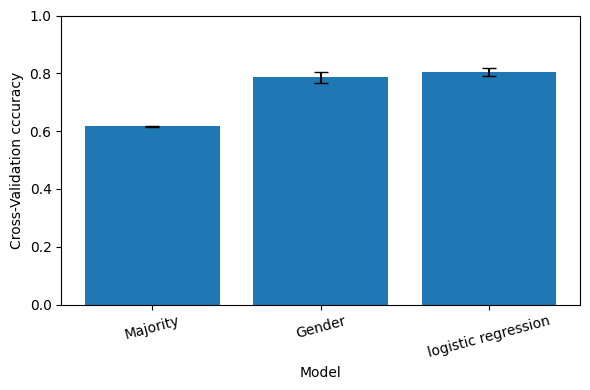

In [46]:
plt.figure(figsize=(6, 4))

plt.bar(cv_results["Model"], cv_results["Mean accuracy"],yerr=cv_results['std accuracy'],capsize=5)
plt.ylabel("Cross-Validation cccuracy")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [47]:
fold_comparison = pd.DataFrame({'Fold': np.arange(1,6), 'Majority': majority_cv_scores, 'Gender': gender_scores, 'logitic regression': logreg_cv_scores})
fold_comparison

,Fold,Majority,Gender,logitic regression
0,1,0.614525,0.787709,0.793296
1,2,0.617978,0.775281,0.803371
2,3,0.617978,0.786517,0.797753
3,4,0.617978,0.764045,0.792135
4,5,0.612360,0.820225,0.831461


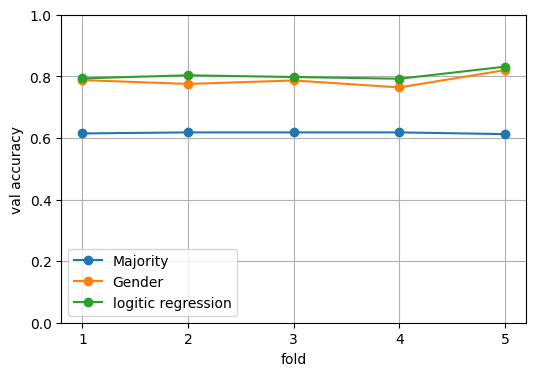

In [48]:
fold_comparison.set_index("Fold").plot(marker="o",figsize=(6, 4))

plt.ylabel("val accuracy")
plt.xlabel("fold")
plt.ylim(0, 1)
plt.xticks(range(1, 6))
plt.grid(True)
plt.show()

In [49]:
#feature engineering
def add_features(df):
    df=df.copy()
    df['family_size'] = df['SibSp'] + df['Parch'] +1 #including the passenger itself
    df['is_alone'] = (df['family_size'] ==1).astype(int)
    df['title'] = df['Name'].str.extract(r',\s*([^.]*)\.',expand=False).str.strip()
    return df

train_features = add_features(train_df)
train_features.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,family_size,is_alone,title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,0,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,0,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,1,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,0,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,1,Mr


In [50]:
train_features['title'].value_counts(dropna=False)

title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [51]:
train_features.groupby('title')['Survived'].agg(['count', 'mean']).sort_values('count', ascending=False)

,count,mean
title,,
Mr,517,0.156673
Miss,182,0.697802
Mrs,125,0.792000
Master,40,0.575000
Dr,7,0.428571
Rev,6,0.000000
Mlle,2,1.000000
Major,2,0.500000
Col,2,0.500000


In [52]:
def add_features(df):
    df=df.copy()
    df['family_size'] = df['SibSp'] + df['Parch'] +1 #including the passenger itself
    df['is_alone'] = (df['family_size'] ==1).astype(int)
    df['title'] = df['Name'].str.extract(r',\s*([^.]*)\.',expand=False).str.strip()
    common_titles = ['Mr', 'Mrs', 'Miss', 'Master']
    df['title'] = df['title'].where(df['title'].isin(common_titles), 'rare')
    return df


In [53]:
from sklearn.preprocessing import FunctionTransformer

feature_engineer = FunctionTransformer(add_features, validate=False)
numerical_features_ = ['Age', 'SibSp', 'Parch', 'Fare', 'family_size', 'is_alone']
categorical_features_ = ['Pclass', 'Sex', 'Embarked', 'title']
preprocessing_features = ColumnTransformer(transformers=[('num', numerical_transformer, numerical_features_), ('cat', categorical_transformer, categorical_features_)])
logreg_ = Pipeline(steps=[('feature_engineering', feature_engineer), ('preprocessor', preprocessing_features), ('classifier', LogisticRegression(max_iter=1000, random_state=42))])
logreg_cv =cross_val_score(logreg_, train_df.drop(columns="Survived"), train_df['Survived'], cv=cv, scoring='accuracy', n_jobs=-1)
print('accuracy:', logreg_cv, 'mean accuracy:', logreg_cv.mean(), 'std accuracy:', logreg_cv.std())

accuracy: [0.83240223 0.80898876 0.8258427  0.82022472 0.8258427 ] mean accuracy: 0.8226602222082733 std accuracy: 0.00784861181019221


In [54]:
cv_results = pd.DataFrame({'Model': ['Majority', 'Gender', 'logistic regression', 'logistic regression feature engineered'],
                          'Mean accuracy': [majority_cv_scores.mean(), gender_scores.mean(), logreg_cv_scores.mean(), logreg_cv.mean()],
                          'std accuracy': [majority_cv_scores.std(), gender_scores.std(), logreg_cv_scores.std(), logreg_cv.std()]})
cv_results.sort_values('Mean accuracy', ascending=False).reset_index(drop=True)

,Model,Mean accuracy,std accuracy
0,logistic regression feature engineered,0.822660,0.007849
1,logistic regression,0.803603,0.014478
2,Gender,0.786755,0.018807
3,Majority,0.616163,0.002325


In [55]:
fold_comparison = pd.DataFrame({'Fold': np.arange(1,6), 'Majority': majority_cv_scores, 'Gender': gender_scores, 'logitic regression': logreg_cv_scores, 'logistic regression feature engineered': logreg_cv})
fold_comparison

,Fold,Majority,Gender,logitic regression,logistic regression feature engineered
0,1,0.614525,0.787709,0.793296,0.832402
1,2,0.617978,0.775281,0.803371,0.808989
2,3,0.617978,0.786517,0.797753,0.825843
3,4,0.617978,0.764045,0.792135,0.820225
4,5,0.612360,0.820225,0.831461,0.825843


In [56]:
#compare diff ML models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV

In [57]:
#KNN
knn_pipeline = Pipeline(steps=[("feature_engineering", feature_engineer),('preprocessor', preprocessing_features),("classifier", KNeighborsClassifier())])
knn_param_grid = {"classifier__n_neighbors": [3, 5, 7, 11, 15], "classifier__weights": ["uniform", "distance"]}
knn_search = GridSearchCV(estimator=knn_pipeline, param_grid=knn_param_grid, scoring="accuracy", cv=cv, n_jobs=-1, refit=True)
knn_search.fit(train_df.drop(columns='Survived'), train_df['Survived'])
print(knn_search.best_params_, knn_search.best_score_)

{'classifier__n_neighbors': 5, 'classifier__weights': 'uniform'} 0.8181532860460736


In [58]:
#decision tree
tree_pipeline = Pipeline(steps=[("feature_engineering", feature_engineer),('preprocessor', preprocessing_features),("classifier", DecisionTreeClassifier(random_state=42))])
tree_param_grid={"classifier__max_depth": [3, 5, 7, 10, None],"classifier__min_samples_leaf": [1, 2, 5, 10, 20]}
tree_search = GridSearchCV(estimator=tree_pipeline, param_grid=tree_param_grid, scoring="accuracy", cv=cv, n_jobs=-1,refit=True)
tree_search.fit(train_df.drop(columns='Survived'), train_df['Survived'])
print(tree_search.best_params_, tree_search.best_score_)

{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5} 0.8248948590797817


In [59]:
#random forest
rf_pipeline = Pipeline(steps=[("feature_engineering", feature_engineer),('preprocessor', preprocessing_features),("classifier", RandomForestClassifier(random_state=42,n_jobs=-1))])
rf_param_grid={"classifier__n_estimators": [100, 300],"classifier__max_depth": [5, 10, None],
              "classifier__min_samples_leaf": [1, 2, 5],"classifier__max_features": ["sqrt", 0.5]}
rf_search = GridSearchCV(estimator=rf_pipeline, param_grid=rf_param_grid, scoring='accuracy', cv=cv, n_jobs=-1, refit=True)
rf_search.fit(train_df.drop(columns='Survived'), train_df['Survived'])
print(rf_search.best_params_, rf_search.best_score_)

{'classifier__max_depth': 10, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100} 0.8507250015692674


In [60]:
#extra trees
Et_pipeline = Pipeline(steps=[("feature_engineering", feature_engineer),('preprocessor', preprocessing_features),("classifier", ExtraTreesClassifier(random_state=42,n_jobs=-1))])
Et_param_grid={"classifier__n_estimators": [100, 300],"classifier__max_depth": [5, 10, None],
              "classifier__min_samples_leaf": [1, 2, 5],"classifier__max_features": ["sqrt", 0.5]}
Et_search = GridSearchCV(estimator=Et_pipeline, param_grid=Et_param_grid, scoring='accuracy', cv=cv, n_jobs=-1, refit=True)
Et_search.fit(train_df.drop(columns='Survived'), train_df['Survived'])
print(Et_search.best_params_, Et_search.best_score_)

{'classifier__max_depth': None, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 300} 0.8383842822170611


In [61]:
#svm
svm_pipeline = Pipeline(steps=[("feature_engineering", feature_engineer),('preprocessor', preprocessing_features),("classifier", SVC(kernel="rbf"))])
svm_param_grid={'classifier__C': [0.1, 1, 10, 100], "classifier__gamma": ["scale", 0.001, 0.01, 0.1, 1]}
svm_search = GridSearchCV(estimator=svm_pipeline, param_grid=svm_param_grid, scoring='accuracy', cv=cv, n_jobs=-1, refit=True)
svm_search.fit(train_df.drop(columns='Survived'), train_df['Survived'])
print(svm_search.best_params_, svm_search.best_score_)

{'classifier__C': 100, 'classifier__gamma': 0.01} 0.8372544096415793


In [62]:
#gradient boosting
gb_pipeline = Pipeline(steps=[("feature_engineering", feature_engineer),('preprocessor', preprocessing_features),("classifier", GradientBoostingClassifier(random_state=42))])
gb_param_grid={"classifier__n_estimators": [100, 200], "classifier__learning_rate": [0.03, 0.05, 0.1], 
               "classifier__max_depth": [1, 2, 3], "classifier__min_samples_leaf": [1, 5]}
gb_search = GridSearchCV(estimator=gb_pipeline, param_grid=gb_param_grid, scoring='accuracy', cv=cv, n_jobs=-1, refit=True)
gb_search.fit(train_df.drop(columns='Survived'), train_df['Survived'])
print(gb_search.best_params_, gb_search.best_score_)

{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100} 0.8439959826752872


In [63]:
#xgboost
xgb_pipeline = Pipeline(steps=[("feature_engineering", feature_engineer),('preprocessor', preprocessing_features),
                               ("classifier", XGBClassifier(objective="binary:logistic", eval_metric="logloss",tree_method="hist",random_state=42,n_jobs=-1))])
xgb_param_grid={"classifier__n_estimators": [100, 300], "classifier__learning_rate": [0.05, 0.1], 
               "classifier__max_depth": [2, 3], "classifier__subsample": [0.8, 1.0], "classifier__colsample_bytree": [0.8, 1.0]}
xgb_search = GridSearchCV(estimator=xgb_pipeline, param_grid=xgb_param_grid, scoring='accuracy', cv=cv, n_jobs=-1, refit=True)
xgb_search.fit(train_df.drop(columns='Survived'), train_df['Survived'])
print(xgb_search.best_params_, xgb_search.best_score_)

{'classifier__colsample_bytree': 1.0, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 300, 'classifier__subsample': 0.8} 0.8473479379825498


In [64]:
#lightgbm
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.simplefilter("ignore")

lightgbm_pipeline = Pipeline(steps=[("feature_engineering", feature_engineer),('preprocessor', preprocessing_features),
                               ("classifier", LGBMClassifier(verbosity=-1,random_state=42,n_jobs=1))])
lightgbm_param_grid={"classifier__n_estimators": [100, 300], "classifier__learning_rate": [0.05, 0.1],
                    "classifier__max_depth": [4, 6], "classifier__num_leaves": [7, 15], "classifier__min_child_samples": [10, 20]}
lightgbm_search = GridSearchCV(estimator=lightgbm_pipeline, param_grid=lightgbm_param_grid, scoring='accuracy', cv=cv, n_jobs=1, refit=True)
lightgbm_search.fit(train_df.drop(columns='Survived'), train_df['Survived'])
print(lightgbm_search.best_params_, lightgbm_search.best_score_)

{'classifier__learning_rate': 0.05, 'classifier__max_depth': 4, 'classifier__min_child_samples': 10, 'classifier__n_estimators': 300, 'classifier__num_leaves': 15} 0.8450881928315862


In [65]:
#catboost
catb_pipeline = Pipeline(steps=[("feature_engineering", feature_engineer),('preprocessor', preprocessing_features),
                               ("classifier", CatBoostClassifier(loss_function="Logloss",verbose=False, random_seed=42, thread_count=1, allow_writing_files=False))])
catb_param_grid={"classifier__iterations": [100, 300], "classifier__depth": [3, 4, 6], "classifier__learning_rate": [0.03, 0.05, 0.1], "classifier__l2_leaf_reg": [3, 10]}
catb_search = GridSearchCV(estimator=catb_pipeline, param_grid=catb_param_grid, scoring='accuracy', cv=cv, n_jobs=-1, refit=True)
catb_search.fit(train_df.drop(columns='Survived'), train_df['Survived'])
print(catb_search.best_params_, catb_search.best_score_)

{'classifier__depth': 4, 'classifier__iterations': 300, 'classifier__l2_leaf_reg': 10, 'classifier__learning_rate': 0.1} 0.8540769568765298


In [66]:
searches = {"KNN": knn_search, "Decision Tree": tree_search, "Random Forest": rf_search,
            "Extra Trees": Et_search, "SVM (RBF)": svm_search, "Gradient Boosting": gb_search,
            "XGBoost": xgb_search, "LightGBM": lightgbm_search, "CatBoost": catb_search}

results = []
for name, search in searches.items():
    best_idx = search.best_index_
    results.append({"Model": name, "mean cv accuracy": search.best_score_, 
                    "cv std": search.cv_results_["std_test_score"][best_idx],"Best Parameters": search.best_params_})

results.append({"Model": "Logistic Regression (baseline)", "mean cv accuracy": logreg_cv.mean(), "cv std": logreg_cv.std(), "Best Parameters": "Default C=1.0"})
model_results = (pd.DataFrame(results).sort_values("mean cv accuracy", ascending=False).reset_index(drop=True))
model_results

,Model,mean cv accuracy,cv std,Best Parameters
0,CatBoost,0.854077,0.010293,"{'classifier__depth': 4, 'classifier__iteratio..."
1,Random Forest,0.850725,0.004627,"{'classifier__max_depth': 10, 'classifier__max..."
2,XGBoost,0.847348,0.011631,"{'classifier__colsample_bytree': 1.0, 'classif..."
3,LightGBM,0.845088,0.015968,"{'classifier__learning_rate': 0.05, 'classifie..."
4,Gradient Boosting,0.843996,0.005480,"{'classifier__learning_rate': 0.1, 'classifier..."
5,Extra Trees,0.838384,0.012996,"{'classifier__max_depth': None, 'classifier__m..."
6,SVM (RBF),0.837254,0.011329,"{'classifier__C': 100, 'classifier__gamma': 0.01}"
7,Decision Tree,0.824895,0.013252,"{'classifier__max_depth': 10, 'classifier__min..."
8,Logistic Regression (baseline),0.822660,0.007849,Default C=1.0
9,KNN,0.818153,0.021700,"{'classifier__n_neighbors': 5, 'classifier__we..."


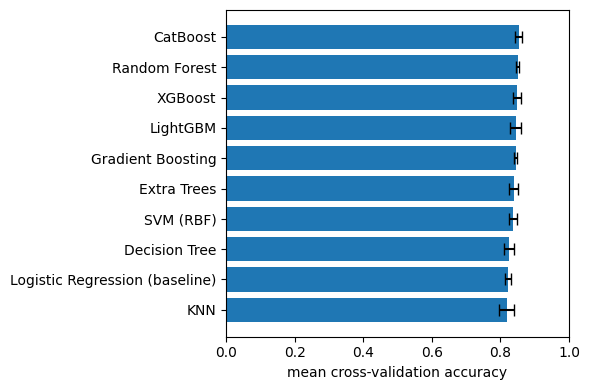

In [67]:
plt.figure(figsize=(6, 4))

plt.barh(model_results["Model"],model_results["mean cv accuracy"],xerr=model_results["cv std"],capsize=4)
plt.xlabel("mean cross-validation accuracy")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [68]:
baseline_accuracy = logreg_cv.mean()
model_results["Improvement vs LR"] = ( model_results["mean cv accuracy"] - baseline_accuracy)
model_results.round(4)

,Model,mean cv accuracy,cv std,Best Parameters,Improvement vs LR
0,CatBoost,0.8541,0.0103,"{'classifier__depth': 4, 'classifier__iteratio...",0.0314
1,Random Forest,0.8507,0.0046,"{'classifier__max_depth': 10, 'classifier__max...",0.0281
2,XGBoost,0.8473,0.0116,"{'classifier__colsample_bytree': 1.0, 'classif...",0.0247
3,LightGBM,0.8451,0.0160,"{'classifier__learning_rate': 0.05, 'classifie...",0.0224
4,Gradient Boosting,0.8440,0.0055,"{'classifier__learning_rate': 0.1, 'classifier...",0.0213
5,Extra Trees,0.8384,0.0130,"{'classifier__max_depth': None, 'classifier__m...",0.0157
6,SVM (RBF),0.8373,0.0113,"{'classifier__C': 100, 'classifier__gamma': 0.01}",0.0146
7,Decision Tree,0.8249,0.0133,"{'classifier__max_depth': 10, 'classifier__min...",0.0022
8,Logistic Regression (baseline),0.8227,0.0078,Default C=1.0,0.0000
9,KNN,0.8182,0.0217,"{'classifier__n_neighbors': 5, 'classifier__we...",-0.0045


In [69]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.simplefilter("ignore")

X = train_df.drop(columns='Survived')
y = train_df['Survived']
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
shortlisted_models = {'Random forest': rf_search, 'XGBoost': xgb_search, 
                      'LightGBM': lightgbm_search, 'CatBoost': catb_search}

shortlisted_results=[]
for name, search in shortlisted_models.items():
    scores=cross_validate(search, X, y, cv=outer_cv, scoring={'accuracy': 'accuracy', 'f1': 'f1'},
                         return_train_score=True, n_jobs=1, error_score='raise')
    shortlisted_results.append({'model': name, 'train_accuracy': scores['train_accuracy']. mean(), 'test_accuracy': scores['test_accuracy']. mean(),
                               'test_std': scores['test_accuracy'].std(), 'f1': scores['test_f1'].mean(),
                               'accuracy_gap': (scores['train_accuracy'] - scores['test_accuracy']).mean()})

shortlisted_results = pd.DataFrame(shortlisted_results)
shortlisted_results.sort_values('test_accuracy', ascending=False)


,model,train_accuracy,test_accuracy,test_std,f1,accuracy_gap
2,LightGBM,0.903190,0.841730,0.018753,0.782109,0.061460
1,XGBoost,0.871211,0.833846,0.024240,0.770879,0.037365
0,Random forest,0.894787,0.829383,0.021648,0.765209,0.065404
3,CatBoost,0.900388,0.823765,0.023102,0.759894,0.076623


In [70]:
import optuna
import warnings
import os
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.simplefilter("ignore")

X = train_df.drop(columns='Survived')
y = train_df['Survived']

optuna_cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
optuna.logging.set_verbosity(optuna.logging.WARNING)
def optuna_model(trial, model_name):
    if model_name=='Random Forest':
        return RandomForestClassifier(n_estimators=trial.suggest_int('n_estimators', 100, 600, step=100),
                                     max_depth=trial.suggest_categorical('max_depth', [4, 6, 8, 10, 15, None]),
                                     min_samples_split=trial.suggest_int('min_samples_split', 2, 12),
                                     min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 8),
                                     max_features=trial.suggest_categorical('max_features', ['sqrt', 0.5, 0.8]),
                                     max_samples=trial.suggest_float('max_samples', 0.7, 1.0), 
                                     bootstrap=True, random_state=42, n_jobs=1)

    elif model_name == 'XGBoost':
        return XGBClassifier(n_estimators=trial.suggest_int('n_estimators', 100, 700, step=100),
                            learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
                            max_depth=trial.suggest_int('max_depth', 2, 6),
                            min_child_weight=trial.suggest_int('min_child_weight',1,10),
                            subsample=trial.suggest_float('subsample', 0.6, 1.0),
                            colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
                            reg_alpha=trial.suggest_float('reg_alpha', 1e-4, 10, log=True),
                            reg_lambda=trial.suggest_float('reg_lambda',1e-3, 20, log=True),
                            objective="binary:logistic", eval_metric="logloss", tree_method="hist", random_state=42, n_jobs=1)

    elif model_name == 'LightGBM':
        return LGBMClassifier(n_estimators=trial.suggest_int('n_estimators', 100, 700, step=100),
                             learning_rate = trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
                             max_depth = trial.suggest_int('max_depth', 3, 8),
                             num_leaves=trial.suggest_int('num_leaves', 7, 31),
                             min_child_samples = trial.suggest_int('min_child_samples', 10, 50),
                             subsample=trial.suggest_float('subsample', 0.7, 1.0),
                             subsample_freq=1, colsample_bytree=trial.suggest_float('colsample_bytree', 0.7, 1.0),
                             reg_alpha=trial.suggest_float('reg_alpha', 1e-4, 10, log=True),
                             reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 20, log=True),
                             verbosity=-1, random_state=42, n_jobs=1)
    elif model_name == 'CatBoost':
        return CatBoostClassifier(iterations=trial.suggest_int('iterations', 100, 700, step= 100),
                                 depth = trial.suggest_int('depth', 3, 7),
                                 learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
                                 l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 1, 20, log=True),
                                 random_strength=trial.suggest_float('random_strength', 0.01, 5, log=True),
                                 loss_function='Logloss', verbose=False, random_seed=42, thread_count=1, allow_writing_files=False)
    else:
        raise ValueError('unknown model name!')


def objective(trial, model_name):
    classifier = optuna_model(trial, model_name)
    pipeline = Pipeline(steps=[('feature_engineering', clone(feature_engineer)), ('preprocessor', clone(preprocessing_features)), ('classifier', classifier)])
    scores = cross_val_score(pipeline, X, y, cv=optuna_cv, scoring='accuracy', n_jobs=1, error_score='raise')
    trial.set_user_attr('cv_std', float(scores.std()))
    return float(scores.mean())

model_names = ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost']
studies = {}
for model_name in model_names:
    print(f'{model_name}')
    study = optuna.create_study(direction='maximize', sampler= optuna.samplers.TPESampler(seed=42))
    study.optimize(lambda trial: objective(trial, model_name), n_trials=40, show_progress_bar=True)
    studies[model_name] = study
    print('best accuracy:', study.best_value, 'best parameters:', study.best_params)


Random Forest


  0%|          | 0/40 [00:00<?, ?it/s]

best accuracy: 0.857447743393384 best parameters: {'n_estimators': 500, 'max_depth': 10, 'min_samples_split': 9, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_samples': 0.9350297648194673}
XGBoost


  0%|          | 0/40 [00:00<?, ?it/s]

best accuracy: 0.84509446990145 best parameters: {'n_estimators': 600, 'learning_rate': 0.058223096342091094, 'max_depth': 2, 'min_child_weight': 6, 'subsample': 0.96459691802607, 'colsample_bytree': 0.7630282940200935, 'reg_alpha': 0.0018269117531474514, 'reg_lambda': 0.0014375777049335783}
LightGBM


  0%|          | 0/40 [00:00<?, ?it/s]

best accuracy: 0.851829765865294 best parameters: {'n_estimators': 400, 'learning_rate': 0.023927528765580644, 'max_depth': 6, 'num_leaves': 10, 'min_child_samples': 21, 'subsample': 0.8099085529881075, 'colsample_bytree': 0.8368209952651108, 'reg_alpha': 0.8431013932082461, 'reg_lambda': 0.007224419004573213}
CatBoost


  0%|          | 0/40 [00:00<?, ?it/s]

best accuracy: 0.8574665746029753 best parameters: {'iterations': 700, 'depth': 6, 'learning_rate': 0.05134217668636421, 'l2_leaf_reg': 16.529805537487018, 'random_strength': 0.17100597462578898}


In [71]:
optuna_results = []
for model_name, study in studies.items():
    optuna_results.append({"Model": model_name, "Optuna cv accuracy": study.best_value,
                           "Optuna cv std": study.best_trial.user_attrs["cv_std"], 
                           "Best Parameters": study.best_params})
optuna_results = pd.DataFrame(optuna_results)
optuna_results

,Model,Optuna cv accuracy,Optuna cv std,Best Parameters
0,Random Forest,0.857448,0.011188,"{'n_estimators': 500, 'max_depth': 10, 'min_sa..."
1,XGBoost,0.845094,0.018149,"{'n_estimators': 600, 'learning_rate': 0.05822..."
2,LightGBM,0.851830,0.020731,"{'n_estimators': 400, 'learning_rate': 0.02392..."
3,CatBoost,0.857467,0.009074,"{'iterations': 700, 'depth': 6, 'learning_rate..."


In [72]:
best_optuna_pipelines = {}
for model_name, study in studies.items():
    fixed_trial = optuna.trial.FixedTrial(study.best_params)
    best_classifier = optuna_model(fixed_trial, model_name)
    pipeline = Pipeline(steps=[("feature_engineering", clone(feature_engineer)), ("preprocessor", clone(preprocessing_features)), ("classifier", best_classifier)])
    pipeline.fit(X, y)
    best_optuna_pipelines[model_name] = pipeline

In [73]:
from sklearn.metrics import accuracy_score, f1_score

final_results = []
for name, pipeline in best_optuna_pipelines.items():

    y_pred = pipeline.predict(X)
    final_results.append({"Model": name, "Train accuracy": accuracy_score(y, y_pred), 
                          "Train F1": f1_score(y, y_pred), "Optuna cv accuracy": studies[name].best_value,
                          "Optuna cv std": studies[name].best_trial.user_attrs["cv_std"]})

final_results = pd.DataFrame(final_results)
final_results = final_results.sort_values("Optuna cv accuracy",ascending=False)
display(final_results.round(4))

,Model,Train accuracy,Train F1,Optuna cv accuracy,Optuna cv std
3,CatBoost,0.9293,0.9035,0.8575,0.0091
0,Random Forest,0.9080,0.8735,0.8574,0.0112
2,LightGBM,0.8934,0.8536,0.8518,0.0207
1,XGBoost,0.8754,0.8284,0.8451,0.0181


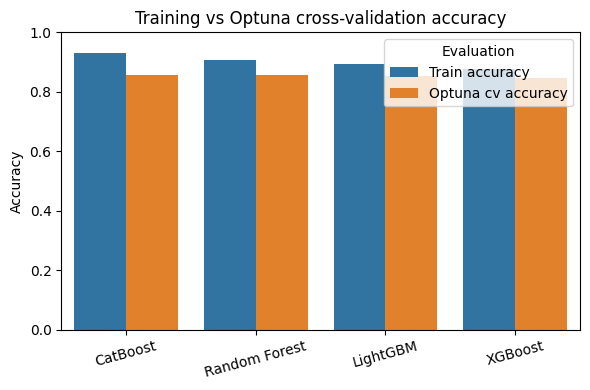

In [74]:
plot_df = final_results.melt(id_vars="Model",value_vars=["Train accuracy", "Optuna cv accuracy"], 
                             var_name="Evaluation", value_name="accuracy")

plt.figure(figsize=(6, 4))
sns.barplot(data=plot_df, x="Model", y="accuracy", hue="Evaluation")
plt.title("Training vs Optuna cross-validation accuracy")
plt.ylabel("Accuracy")
plt.xlabel("")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

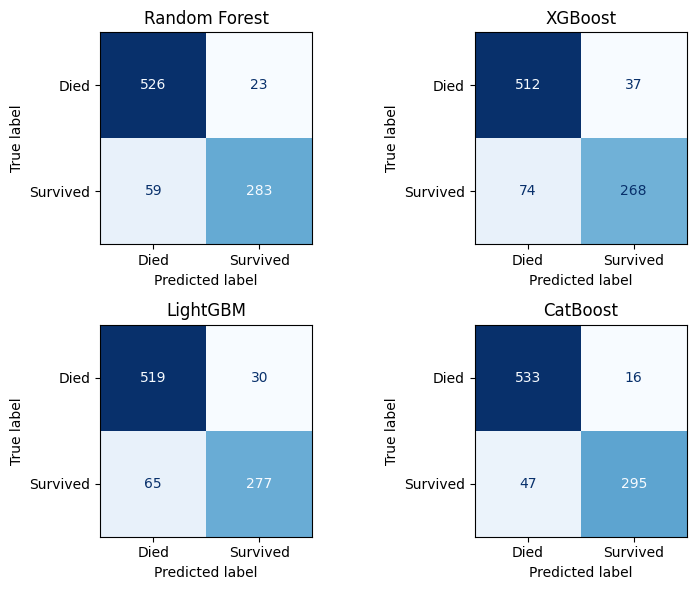

In [75]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
#on training data
fig, axes = plt.subplots(2, 2, figsize=(8, 6))

for ax, (name, pipeline) in zip(axes.flat,best_optuna_pipelines.items()):
    y_pred = pipeline.predict(X)
    ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=["Died", "Survived"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

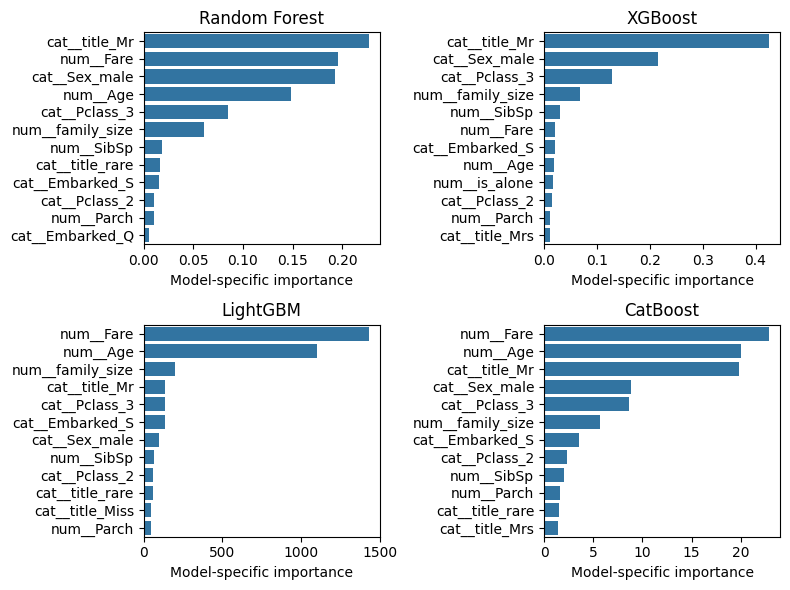

In [76]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))

for ax, (name, pipeline) in zip(axes.flat, best_optuna_pipelines.items()):
    preprocessor = pipeline.named_steps["preprocessor"]
    classifier = pipeline.named_steps["classifier"]
    feature_names = preprocessor.get_feature_names_out()
    importances = classifier.feature_importances_
    importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importances}).sort_values("Importance", ascending=False).head(12)

    sns.barplot(data=importance_df, x="Importance", y="Feature",ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Model-specific importance")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [77]:
import optuna.visualization as vis

for name, study in studies.items():
    fig = vis.plot_optimization_history(study)
    fig.update_layout(title=f"{name} — Optuna optimization history")
    fig.show()

In [78]:
for name, study in studies.items():
    fig = vis.plot_param_importances(study)
    fig.update_layout(title=f"{name} — Hyperparameter Importance")
    fig.show()

In [79]:
for name, study in studies.items():

    print(f"\n{'=' * 60}")
    print(name)
    print(f"Best cv accuracy: {study.best_value:.4f}")
    print(f"Best cv std: {study.best_trial.user_attrs['cv_std']:.4f}")
    print("Best Hyperparameters:")

    for parameter, value in study.best_params.items():
        print(f"  {parameter}: {value}")


Random Forest
Best cv accuracy: 0.8574
Best cv std: 0.0112
Best Hyperparameters:
  n_estimators: 500
  max_depth: 10
  min_samples_split: 9
  min_samples_leaf: 1
  max_features: 0.8
  max_samples: 0.9350297648194673

XGBoost
Best cv accuracy: 0.8451
Best cv std: 0.0181
Best Hyperparameters:
  n_estimators: 600
  learning_rate: 0.058223096342091094
  max_depth: 2
  min_child_weight: 6
  subsample: 0.96459691802607
  colsample_bytree: 0.7630282940200935
  reg_alpha: 0.0018269117531474514
  reg_lambda: 0.0014375777049335783

LightGBM
Best cv accuracy: 0.8518
Best cv std: 0.0207
Best Hyperparameters:
  n_estimators: 400
  learning_rate: 0.023927528765580644
  max_depth: 6
  num_leaves: 10
  min_child_samples: 21
  subsample: 0.8099085529881075
  colsample_bytree: 0.8368209952651108
  reg_alpha: 0.8431013932082461
  reg_lambda: 0.007224419004573213

CatBoost
Best cv accuracy: 0.8575
Best cv std: 0.0091
Best Hyperparameters:
  iterations: 700
  depth: 6
  learning_rate: 0.05134217668636421


In [80]:
#nested cv
X = train_df.drop(columns="Survived")
y = train_df["Survived"]

outer_cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=7)
inner_cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=42)

final_candidates = ["Random Forest","LightGBM","CatBoost"]


In [81]:
nested_optuna_results = []

for model_name in final_candidates:
    outer_scores = []
    for fold, (train_idx, val_idx) in enumerate(outer_cv.split(X, y), start=1):
        X_train = X.iloc[train_idx]
        y_train = y.iloc[train_idx]
        X_val = X.iloc[val_idx]
        y_val = y.iloc[val_idx]

        def objective_nested(trial):
            classifier = optuna_model(trial, model_name)
            pipeline = Pipeline(steps=[("feature_engineering", clone(feature_engineer)), ("preprocessor", clone(preprocessing_features)), ("classifier", classifier)])
            scores = cross_val_score(pipeline, X_train, y_train, cv=inner_cv, scoring="accuracy", n_jobs=1, error_score="raise")
            return scores.mean()

        study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
        study.optimize(objective_nested, n_trials=40, show_progress_bar=True)
        best_classifier = optuna_model(optuna.trial.FixedTrial(study.best_params), model_name)

        best_pipeline = Pipeline(steps=[("feature_engineering", clone(feature_engineer)), ("preprocessor", clone(preprocessing_features)), ("classifier", best_classifier)])
        best_pipeline.fit(X_train, y_train)
        predictions = best_pipeline.predict(X_val)
        accuracy = accuracy_score(y_val, predictions)
        outer_scores.append(accuracy)
        print(f"{model_name} | Fold {fold} | " f"accuracy: {accuracy:.4f}")

    nested_optuna_results.append({"Model": model_name,"nested accuracy": np.mean(outer_scores),
                                  "nested std": np.std(outer_scores), "fold scores": outer_scores})

nested_optuna_results = pd.DataFrame(nested_optuna_results)

display(nested_optuna_results.sort_values("nested accuracy", ascending=False).style.format({"nested accuracy": "{:.3f}", 
                                                                                            "nested std": "{:.3f}", 
                                                                                            "fold scores": lambda scores: [round(s, 3) for s in scores]}))

  0%|          | 0/40 [00:00<?, ?it/s]

Random Forest | Fold 1 | accuracy: 0.8659


  0%|          | 0/40 [00:00<?, ?it/s]

Random Forest | Fold 2 | accuracy: 0.7921


  0%|          | 0/40 [00:00<?, ?it/s]

...

  0%|          | 0/40 [00:00<?, ?it/s]

CatBoost | Fold 4 | accuracy: 0.8371


  0%|          | 0/40 [00:00<?, ?it/s]

CatBoost | Fold 5 | accuracy: 0.8539


,Model,nested accuracy,nested std,fold scores
1,LightGBM,0.835,0.026,"[0.86, 0.787, 0.831, 0.848, 0.848]"
2,CatBoost,0.832,0.027,"[0.866, 0.798, 0.803, 0.837, 0.854]"
0,Random Forest,0.829,0.028,"[0.866, 0.792, 0.803, 0.837, 0.848]"


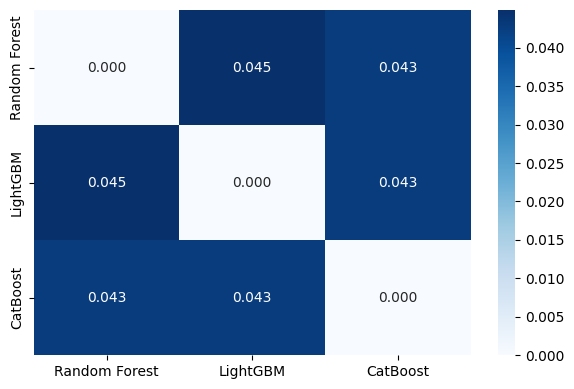

In [82]:
from sklearn.model_selection import cross_val_predict

ensemble_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
rf = best_optuna_pipelines["Random Forest"]
lgbm = best_optuna_pipelines["LightGBM"]
cat = best_optuna_pipelines["CatBoost"]
individual_models = {"Random Forest": rf,"LightGBM": lgbm, "CatBoost": cat}
oof_predictions = {}
for name, model in individual_models.items():
    oof_predictions[name] = cross_val_predict(clone(model), X, y, cv=ensemble_cv, method="predict", n_jobs=1)

disagreement = pd.DataFrame(index=individual_models.keys(), columns=individual_models.keys(), dtype=float)

for name_a, pred_a in oof_predictions.items():
    for name_b, pred_b in oof_predictions.items():
        disagreement.loc[name_a, name_b] = (pred_a != pred_b).mean()

plt.figure(figsize=(6, 4))
sns.heatmap(disagreement.astype(float),annot=True,fmt=".3f",cmap="Blues")
plt.tight_layout()
plt.show()

In [83]:
#ensembling best models!
from sklearn.ensemble import VotingClassifier

ensemble_tree = VotingClassifier(estimators=[("rf", clone(rf)), ("lgbm", clone(lgbm)), ("cat", clone(cat))], voting="soft", n_jobs=1)
ensemble_candidates = {"Random Forest": clone(rf), "LightGBM": clone(lgbm),
                       "CatBoost": clone(cat), "Soft Voting (RF + LGBM + CB)": ensemble_tree}

In [84]:
ensemble_results = []
for name, model in ensemble_candidates.items():
    scores = cross_validate(model, X, y, cv=ensemble_cv, 
                            scoring={"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"},
                            n_jobs=1, error_score="raise")

    ensemble_results.append({"Model": name, "cv accuracy": scores["test_accuracy"].mean(),
                             "cv std": scores["test_accuracy"].std(),
                             "cv f1": scores["test_f1"].mean(),
                             "cv ROC AUC": scores["test_roc_auc"].mean()})

ensemble_results = (pd.DataFrame(ensemble_results).sort_values("cv accuracy", ascending=False).reset_index(drop=True))
display(ensemble_results.round(4))

,Model,cv accuracy,cv std,cv f1,cv ROC AUC
0,Soft Voting (RF + LGBM + CB),0.8474,0.0184,0.7885,0.8783
1,LightGBM,0.8429,0.0173,0.7854,0.8770
2,Random Forest,0.8384,0.0262,0.7732,0.8748
3,CatBoost,0.8361,0.0148,0.7768,0.8759


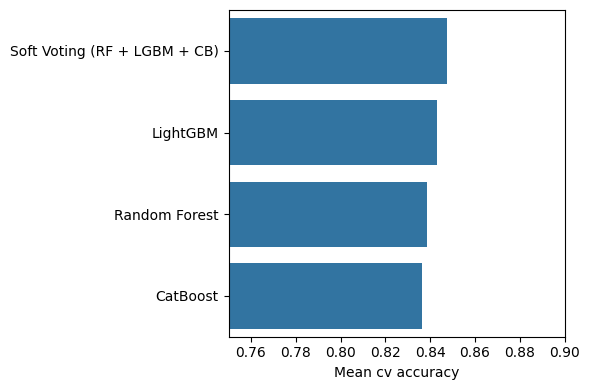

In [85]:
plt.figure(figsize=(6, 4))

sns.barplot(data=ensemble_results, x="cv accuracy", y="Model")

plt.xlabel("Mean cv accuracy")
plt.ylabel("")
plt.xlim(0.75, 0.90)
plt.tight_layout()
plt.show()

In [86]:
final_model = clone(ensemble_candidates["Soft Voting (RF + LGBM + CB)"])
final_model.fit(X, y)
test_predictions = final_model.predict(test_df).astype(int)

submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Survived": np.asarray(test_predictions).astype(int)})

assert submission.shape == (418, 2)
assert submission.columns.tolist() == ["PassengerId", "Survived"]
assert submission["PassengerId"].equals(test_df["PassengerId"])
assert submission["PassengerId"].is_unique
assert submission["Survived"].isin([0, 1]).all()
assert submission["Survived"].notna().all()
print(submission["Survived"].value_counts())
display(submission.head())
submission.to_csv("submission.csv", index=False)

Survived
0    270
1    148
Name: count, dtype: int64


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [ ]:
##train an MLP

In [87]:
from sklearn.neural_network import MLPClassifier

mlp_pipeline = Pipeline(steps=[("feature_engineering", clone(feature_engineer)),
                               ("preprocessor", clone(preprocessing_features)),
                               ("classifier", MLPClassifier(hidden_layer_sizes=(32, 16),
                                                            activation="relu", solver="adam", 
                                                            alpha=0.01, learning_rate_init=0.001,
                                                            max_iter=1000, random_state=42))])

mlp_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
scores = cross_validate(mlp_pipeline, X, y, cv=mlp_cv, scoring={"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"},n_jobs=1)
for metric in ["accuracy", "f1", "roc_auc"]:
    values = scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} ± {values.std():.4f}")

accuracy: 0.7991 ± 0.0133
f1: 0.7239 ± 0.0174
roc_auc: 0.8274 ± 0.0073


In [91]:
mlp_param_grid = {"classifier__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32), (64,32,16), (128,64,32)], 
                  "classifier__alpha": [0.001, 0.01, 0.1], 
                  "classifier__learning_rate_init": [0.0005, 0.001]}

mlp_cv_2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mlp_search = GridSearchCV(estimator=mlp_pipeline, param_grid=mlp_param_grid, 
                          cv=mlp_cv_2, scoring="accuracy", n_jobs=1, refit=True, return_train_score=True)
mlp_search.fit(X, y)
print(mlp_search.best_params_, mlp_search.best_score_)

{'classifier__alpha': 0.1, 'classifier__hidden_layer_sizes': (32,), 'classifier__learning_rate_init': 0.001} 0.8316364321134893


In [94]:
final_mlp = mlp_search.best_estimator_
test_predictions = final_mlp.predict(test_df)

mlp_submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Survived": test_predictions.astype(int)})
assert mlp_submission.shape == (418, 2)
assert mlp_submission["PassengerId"].is_unique
assert mlp_submission["Survived"].isin([0, 1]).all()
assert mlp_submission["Survived"].notna().all()

mlp_submission.to_csv("submission_mlp.csv", index=False)

print("accuracy:", mlp_search.best_score_)
print(mlp_submission["Survived"].value_counts())
display(mlp_submission.head())

accuracy: 0.8316364321134893
Survived
0    273
1    145
Name: count, dtype: int64


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [95]:
comparison = submission.merge(mlp_submission, on="PassengerId", suffixes=("_Ensemble", "_MLP"), validate="one_to_one")

changed_predictions = comparison[comparison["Survived_Ensemble"] != comparison["Survived_MLP"]].copy()
print(f"total passengers: {len(comparison)}")
print(f"different predictions: {len(changed_predictions)}")
print(f"agreement: {100 * (1 - len(changed_predictions) / len(comparison)):.2f}%")
display(changed_predictions)

total passengers: 418
different predictions: 35
agreement: 91.63%


,PassengerId,Survived_Ensemble,Survived_MLP
4,896,1,0
6,898,0,1
18,910,1,0
19,911,0,1
23,915,0,1
28,920,1,0
32,924,1,0
39,931,1,0
41,933,1,0
49,941,1,0
